# Tuning BM25: Quora, WANDS and HotpotQA

Can changing BM25's two parameters improve retrieval over `k1=1.2, b=0.75`?
**k1** controls term-frequency saturation; **b** controls document-length normalization
(`b=0` removes it, `b=1` applies full normalization).

We compare nine `(k1, b)` pairs on top of the field weights from
[`field_weighting.ipynb`](field_weighting.ipynb). Each field has its own BM25 index;
we add its raw score multiplied by its fixed weight. This is not BM25F.
**The same candidate `(k1, b)` is applied to every field**; field weights are not retuned.
Lowercase regex `\w+` + Porter stemming and Lucene BM25 stay fixed.

| Dataset | Frozen field weights | Source |
|---|---|---|
| Quora | text=1 | Only usable text field; no relative weight tuning |
| WANDS | name=1, category=0.5, description=0.25, class=0.25, features=0.25 | Most frequent five-field choice (6/10 folds) in the saved run |
| HotpotQA | title=0.5, text=1 | Selected on dev; also chosen in all ten dev folds |

The baseline is **these same field weights with `k1=1.2, b=0.75`**, not concatenated text.
This measures what parameter tuning adds after field weighting.

| Dataset | Parameter selection | Main comparison |
|---|---|---|
| Quora / HotpotQA | Highest mean dev nDCG@10 | Default vs. frozen dev-selected parameters on test |
| WANDS | Five seeds × two-way two-fold query CV | Default vs. tuned out-of-fold (OOF) scores |

Compare methods within each dataset. WANDS uses graded nDCG and Exact-only MRR; BEIR uses
binary relevance. Selecting the best setting and reporting its score on the same queries would
be optimistic, so full-grid WANDS scores are exploratory only.

**WANDS limitation:** the frozen modal weights were chosen using these same queries in the earlier
experiment. The new CV holds out queries for `k1`/`b` selection only; it does not remove that earlier
weight-selection exposure. Treat WANDS as a conditional, exploratory follow-up, not an unbiased
evaluation of the complete two-stage tuning process. That would require nested tuning or new queries.

## 1. Setup

**Prepared without execution.** Run from the project root or `retrieval/`, or set `ROOT` below.
WANDS reads local TSV files (or `datasets.zip`); BEIR reads local parquet files or downloads missing
datasets when run. The complete corpus is always indexed, including HotpotQA's 5.23M documents.
Field tokens stay in RAM and one parameter setting’s field indexes are held at a time. Each grid
setting builds one index per active field (45 builds for WANDS, 18 for HotpotQA, plus BEIR test
rebuilds). Full-corpus scoring and indexing need substantial RAM and time.

In [1]:
# Install in the active kernel if needed:
# %pip install "bm25s==0.3.16" numpy pandas nltk datasets pyarrow tqdm matplotlib
from pathlib import Path
from array import array
from functools import lru_cache
from itertools import product
from zipfile import ZipFile
from importlib.metadata import version
import gc, json, re
import numpy as np
import pandas as pd
import bm25s
from datasets import Dataset, load_dataset
from nltk.stem import PorterStemmer
from tqdm.auto import tqdm
from IPython.display import display

ROOT = None  # Or Path('/path/to/e2e-search-lab').
if ROOT is None:
    ROOT = next((p for p in [Path.cwd(), Path.cwd().parent]
                 if (p/'datasets').is_dir() or (p/'datasets.zip').is_file()), Path.cwd())
ROOT = Path(ROOT).expanduser().resolve()
DATASETS = ['quora', 'wands', 'hotpotqa']
# Frozen from the saved field_weighting.ipynb results; explicit for reproducibility.
FIELD_WEIGHTS = {
    'quora': {'text': 1.0},
    'wands': {'product_name': 1.0, 'category hierarchy': 0.5,
              'product_description': 0.25, 'product_class': 0.25, 'product_features': 0.25},
    'hotpotqa': {'title': 0.5, 'text': 1.0},
}
WEIGHT_SOURCE = 'retrieval/field_weighting.ipynb (saved run, November 27, 2026)'
DEFAULT = (1.2, 0.75)
# Default comes first, so exact selection ties prefer it.
GRID = [DEFAULT] + [p for p in product((0.6, 1.2, 2.0), (0.0, 0.75, 1.0)) if p != DEFAULT]
SEEDS, K, CHUNK = (0, 1, 2, 3, 4), 100, 4096
METRICS = ['nDCG@10', 'MRR@10', 'Recall@10', 'Recall@100']
PACKAGES = {p: version(p) for p in ['bm25s', 'numpy', 'pandas', 'nltk', 'datasets']}
assert set(DATASETS) <= {'quora', 'wands', 'hotpotqa'}
print('Root:', ROOT, '| settings:', len(GRID), '| packages:', PACKAGES)

/opt/homebrew/anaconda3/envs/llm_optimization/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Root: /Users/eteper/Downloads/projects/e2e-search-lab | settings: 9 | packages: {'bm25s': '0.3.16', 'numpy': '2.5.2', 'pandas': '3.0.5', 'nltk': '3.10.4', 'datasets': '5.0.1'}


## 2. Load documents and query splits

BEIR dev/test query IDs must be disjoint. Self-matches are excluded for BEIR only.
Queries without a positive judgment are excluded; duplicate judgments keep their highest grade.
WANDS has no separate test split here, so it uses query-level cross-validation.

In [2]:
def load_beir(name):
    folder = ROOT/'datasets'/name
    if (folder/'corpus.parquet').exists():
        corpus = Dataset.from_parquet(str(folder/'corpus.parquet'))
        queries = pd.read_parquet(folder/'queries.parquet')
        rels = {s: pd.read_parquet(folder/f'qrels_{s}.parquet') for s in ['dev','test']}
    else:
        corpus = load_dataset(f'BeIR/{name}', 'corpus', split='corpus')
        queries = load_dataset(f'BeIR/{name}', 'queries', split='queries').to_pandas()
        rels = {s: pd.read_csv(f'https://huggingface.co/datasets/BeIR/{name}-qrels/resolve/main/{s}.tsv',
                              sep='\t', dtype={'query-id': str, 'corpus-id': str}) for s in ['dev','test']}
    query_map = dict(zip(queries['_id'].astype(str), queries['text'].fillna('').astype(str)))
    splits = {}
    for split, rel in rels.items():
        assert rel['score'].notna().all()
        rel['query-id'], rel['corpus-id'] = rel['query-id'].astype(str), rel['corpus-id'].astype(str)
        rel = rel.groupby(['query-id','corpus-id'], as_index=False)['score'].max()
        qrels = {q: dict(zip(g['corpus-id'], g['score'].astype(int))) for q,g in rel.groupby('query-id', sort=False)}
        qids = [q for q,g in qrels.items() if any(v > 0 for v in g.values())]
        assert qids and set(qids) <= query_map.keys()
        splits[split] = {'qids': qids, 'qrels': qrels}
    assert set(splits['dev']['qids']).isdisjoint(splits['test']['qids']), 'Dev/test query overlap.'
    needed = {d for s in splits.values() for q in s['qids'] for d in s['qrels'][q]}
    needed.update(q for s in splits.values() for q in s['qids'])
    positions = {}
    for start in range(0, len(corpus), CHUNK):
        for offset, doc in enumerate(corpus[start:start+CHUNK]['_id']):
            doc = str(doc)
            if doc in needed:
                assert doc not in positions, 'Duplicate corpus ID.'
                positions[doc] = start+offset
    for data in splits.values():
        assert all(d in positions for q in data['qids'] for d,v in data['qrels'][q].items() if v > 0)
        data['grades'] = [{positions[d]:v for d,v in data['qrels'][q].items() if d in positions} for q in data['qids']]
        data['queries'] = [query_map[q] for q in data['qids']]
        data['excluded'] = [positions.get(q,-1) for q in data['qids']]
        del data['qrels']
    return corpus, splits

def load_data(name):
    if name != 'wands':
        corpus, splits = load_beir(name)
        return corpus, splits, list(FIELD_WEIGHTS[name]), False
    def table(filename):
        path = ROOT/'datasets/wands'/filename
        if path.exists():
            return pd.read_csv(path, sep='\t')
        with ZipFile(ROOT/'datasets.zip') as z, z.open(f'datasets/wands/{filename}') as f:
            return pd.read_csv(f, sep='\t')
    docs, queries, rel = [table(f'{s}.csv') for s in ['product', 'query', 'label']]
    fields = list(FIELD_WEIGHTS[name])
    assert docs.product_id.is_unique and queries.query_id.is_unique
    docs[fields] = docs[fields].fillna('').astype(str)
    corpus = Dataset.from_pandas(docs[fields].assign(_id=docs.product_id.astype(str)), preserve_index=False)
    positions = {str(d): i for i, d in enumerate(docs.product_id)}
    rel = rel.assign(qid=rel.query_id.astype(str), doc=rel.product_id.astype(str).map(positions),
                     grade=rel.label.map({'Exact': 2, 'Partial': 1, 'Irrelevant': 0}))
    assert rel[['doc', 'grade']].notna().all().all()
    rel = rel.groupby(['qid', 'doc'], as_index=False).grade.max()
    grades = {q: dict(zip(g.doc.astype(int), g.grade.astype(int))) for q, g in rel.groupby('qid')}
    query_map = dict(zip(queries.query_id.astype(str), queries['query'].fillna('').astype(str)))
    qids = [q for q, g in grades.items() if any(v > 0 for v in g.values())]
    assert len(qids) >= 4 and set(qids) <= query_map.keys()
    data = {'qids': qids, 'queries': [query_map[q] for q in qids],
            'grades': [grades[q] for q in qids], 'excluded': [-1]*len(qids)}
    return corpus, {'all': data}, fields, True

## 3. Fixed tokenizer, full-corpus scoring

Tokenize each field once, then rebuild its BM25 index for each parameter pair. Add the fixed-weight
field scores over the entire corpus before selecting top-k; no per-field candidate truncation is used. Retrieve up to 100 positive-score documents; ties favor the lower corpus row.
Unjudged documents count as irrelevant. WANDS nDCG uses `2**grade - 1` (Exact=2, Partial=1),
MRR counts Exact only and excludes queries without an Exact product; recall counts both grades.

In [3]:
porter = PorterStemmer()

@lru_cache(maxsize=200_000)
def stem(word):
    return porter.stem(word)


def tokenize(text):
    return [stem(t) for t in re.findall(r'\w+', text.lower())]


def corpus_tokens(corpus, fields):
    vocab, ids = {}, []
    for start in tqdm(range(0, len(corpus), CHUNK), desc='Tokenizing corpus'):
        batch = corpus[start:start+CHUNK]
        for row in zip(*(batch[f] for f in fields)):
            text = ' '.join(str(v or '') for v in row)
            ids.append(array('I', (vocab.setdefault(t, len(vocab)) for t in tokenize(text))))
    assert vocab
    stem.cache_clear()
    return bm25s.tokenization.Tokenized(ids, vocab)


def build(tokens, params):
    models = {}
    for field, field_tokens in tokens.items():
        index = bm25s.BM25(method='lucene', k1=params[0], b=params[1])
        index.index(field_tokens, show_progress=True)
        models[field] = index
    return models


def topk(scores):
    valid = np.flatnonzero(np.isfinite(scores) & (scores > 0))
    k = min(K, len(valid))
    if not k:
        return np.array([], dtype=int)
    cutoff = np.partition(scores[valid], len(valid)-k)[len(valid)-k]
    above = valid[scores[valid] > cutoff]
    tied = valid[scores[valid] == cutoff][:k-len(above)]
    ids = np.concatenate([above, tied])
    return ids[np.lexsort((ids, -scores[ids]))]


def score(models, data, graded, weights, n_docs):
    values = np.zeros((len(data['qids']), len(METRICS)))
    discounts = 1/np.log2(np.arange(2, 12))
    for qi, text in enumerate(tqdm(data['queries'], desc='Scoring queries')):
        query_tokens = tokenize(text)
        scores = np.zeros(n_docs, dtype=np.float32)
        for field, index in models.items():
            known = [t for t in query_tokens if t in index.vocab_dict]
            if known:
                scores += weights[field]*index.get_scores(known)
        if data['excluded'][qi] >= 0:
            scores[data['excluded'][qi]] = -np.inf
        ids = topk(scores)
        grades = data['grades'][qi]
        g = np.array([grades.get(int(d), 0) for d in ids])
        ideal = np.array(sorted(grades.values(), reverse=True)[:10])
        gain = lambda x: 2.0**x-1 if graded else (x > 0).astype(float)
        idcg = np.dot(gain(ideal), discounts[:len(ideal)])
        ndcg = np.dot(gain(g[:10]), discounts[:min(10, len(g))])/idcg
        exact = 2 if graded else 1
        hits = np.flatnonzero(g[:10] >= exact)
        rr = 1/(hits[0]+1) if len(hits) else 0.0
        if graded and not any(v == 2 for v in grades.values()):
            rr = np.nan
        nrel = sum(v > 0 for v in grades.values())
        values[qi] = [ndcg, rr, (g[:10] > 0).sum()/nrel, (g > 0).sum()/nrel]
    return values

## 4. Select parameters and compare

Keep the imported field weights fixed in both systems. For BEIR, score the parameter grid on dev and evaluate only the default and selected settings on test.
For WANDS, select separately on each training half and use the other half's scores; every query
receives an OOF score for each seed. Average those per-query scores across seeds for the summary.
WANDS OOF applies to parameter selection only, conditional on the previously chosen field weights.
The seeds reuse queries: they are not five independent test sets. No confidence interval is claimed.

A positive nDCG difference is not enough on its own: check MRR and recall as well. This coarse grid
finds the best tested pair, not a universal optimum.

In [4]:
def means(values):
    return {m: float(np.nanmean(values[:, i])) if np.isfinite(values[:, i]).any() else np.nan
            for i, m in enumerate(METRICS)}


all_rows, results = [], {}
for name in DATASETS:
    corpus, splits, fields, graded = load_data(name)
    tune_split = 'all' if graded else 'dev'
    data = splits[tune_split]
    print(f"{name}: {len(corpus):,} documents; splits:", {s: len(d['qids']) for s,d in splits.items()})
    weights = FIELD_WEIGHTS[name]
    print('Frozen field weights:', weights)
    tokens = {f: corpus_tokens(corpus, [f]) for f in fields}
    scores_by_param = {}
    for params in GRID:
        print('k1, b:', params)
        index = build(tokens, params)
        scores_by_param[params] = score(index, data, graded, weights, len(corpus))
        del index
        gc.collect()
    grid = pd.DataFrame([{'k1': p[0], 'b': p[1], **means(v)} for p,v in scores_by_param.items()])
    display(grid.sort_values('nDCG@10', ascending=False).round(4))
    selections = []
    selected = None
    if graded:
        runs = []
        for seed in SEEDS:
            folds = np.array_split(np.random.default_rng(seed).permutation(len(data['qids'])), 2)
            oof = np.full_like(scores_by_param[DEFAULT], np.nan)
            for fold in range(2):
                tune, held = folds[fold], folds[1-fold]
                chosen = max(GRID, key=lambda p: scores_by_param[p][tune, 0].mean())
                oof[held] = scores_by_param[chosen][held]
                selections.append({'seed': seed, 'held_fold': 1-fold, 'k1': chosen[0], 'b': chosen[1]})
            assert np.isfinite(oof[:, 0]).all()
            runs.append(oof)
        # Missing Exact judgments produce NaN MRR for the same queries in every run.
        evaluated = {'Weighted default': scores_by_param[DEFAULT], 'Weighted + tuned parameters (conditional OOF)': np.mean(runs, axis=0)}
        evaluation = 'conditional OOF (parameters only)'
    else:
        selected = max(GRID, key=lambda p: scores_by_param[p][:, 0].mean())
        selections.append({'split': 'dev', 'k1': selected[0], 'b': selected[1]})
        data, evaluation = splits['test'], 'test'
        test = {}
        for params in dict.fromkeys([DEFAULT, selected]):
            index = build(tokens, params)
            test[params] = score(index, data, graded, weights, len(corpus))
            del index
            gc.collect()
        evaluated = {'Weighted default': test[DEFAULT], 'Weighted + dev-selected parameters': test[selected]}
    rows, per_query = [], []
    for method, values in evaluated.items():
        rows.append({'dataset': name, 'evaluation': evaluation, 'method': method, **means(values),
                     'delta_nDCG_pp': 100*(values[:, 0]-evaluated['Weighted default'][:, 0]).mean()})
        for qi, qid in enumerate(data['qids']):
            per_query.append({'method': method, 'query_id': qid, **dict(zip(METRICS, values[qi]))})
    manifest = {'dataset': name, 'fields': fields, 'corpus_rows': len(corpus),
                'field_weights': weights, 'weight_source': WEIGHT_SOURCE,
                'shared_parameters_across_fields': True,
                'corpus_fingerprint': corpus._fingerprint, 'grid': GRID, 'default': DEFAULT,
                'selected': selected, 'selection_metric': 'nDCG@10', 'evaluation': evaluation,
                'seeds': SEEDS, 'k': K, 'method': 'lucene', 'tokenizer': 'lowercase regex + Porter',
                'packages': PACKAGES, 'query_ids': {s: d['qids'] for s,d in splits.items()}}
    results[name] = {
        'selection_grid': grid, 'selected_parameters': pd.DataFrame(selections),
        'per_query': pd.DataFrame(per_query), 'summary': pd.DataFrame(rows), 'manifest': manifest,
    }
    display(pd.DataFrame(rows).round(4))
    all_rows.extend(rows)
    del tokens, corpus, scores_by_param
    stem.cache_clear()
    gc.collect()

summary = pd.DataFrame(all_rows)
display(summary.round(4))

quora: 522,931 documents; splits: {'dev': 5000, 'test': 10000}
Frozen field weights: {'text': 1.0}


Tokenizing corpus: 100%|██████████| 128/128 [00:02<00:00, 60.20it/s]


k1, b: (1.2, 0.75)


Scoring queries: 100%|██████████| 5000/5000 [00:18<00:00, 273.87it/s]            


k1, b: (0.6, 0.0)


Scoring queries: 100%|██████████| 5000/5000 [00:16<00:00, 298.22it/s]            


... (59 outputs left out)

,k1,b,nDCG@10,MRR@10,Recall@10,Recall@100
2,0.6,0.75,0.6564,0.8266,0.6748,0.7948
3,0.6,1.00,0.6399,0.8064,0.6646,0.7861
0,1.2,0.75,0.6242,0.7890,0.6502,0.7791
1,0.6,0.00,0.6196,0.7851,0.6479,0.7784
7,2.0,0.75,0.5855,0.7427,0.6195,0.7605
4,1.2,0.00,0.5820,0.7421,0.6162,0.7635
5,1.2,1.00,0.5750,0.7314,0.6105,0.7547
6,2.0,0.00,0.5333,0.6840,0.5737,0.7362
8,2.0,1.00,0.5020,0.6449,0.5442,0.7113


Scoring queries: 100%|██████████| 7405/7405 [29:30<00:00,  4.18it/s]               


,dataset,evaluation,method,nDCG@10,MRR@10,Recall@10,Recall@100,delta_nDCG_pp
0,hotpotqa,test,Weighted default,0.5980,0.7657,0.6220,0.7583,0.0000
1,hotpotqa,test,Weighted + dev-selected parameters,0.6323,0.8049,0.6521,0.7772,3.4265


,dataset,evaluation,method,nDCG@10,MRR@10,Recall@10,Recall@100,delta_nDCG_pp
0,quora,test,Weighted default,0.7998,0.7940,0.8973,0.9741,0.0000
1,quora,test,Weighted + dev-selected parameters,0.8011,0.7955,0.8978,0.9744,0.1304
2,wands,conditional OOF (parameters only),Weighted default,0.7239,0.7031,0.0642,0.4132,0.0000
3,wands,conditional OOF (parameters only),Weighted + tuned parameters (conditional OOF),0.7269,0.7033,0.0653,0.4172,0.2937
4,hotpotqa,test,Weighted default,0.5980,0.7657,0.6220,0.7583,0.0000
5,hotpotqa,test,Weighted + dev-selected parameters,0.6323,0.8049,0.6521,0.7772,3.4265


## Reading the results

- **Weighted default → tuned parameters:** the additional effect of `k1` and `b` with field weights fixed.
- **Selected parameters:** stable WANDS fold choices support a clearer interpretation than scattered choices.
- **Recall:** a small nDCG gain can still reduce the relevant documents available to a later reranker.

Results stay in memory in `summary` and `results[dataset]`; no result files are written automatically.
Per-query tables support later paired analysis, and manifests record corpus fingerprints, query IDs and settings. WANDS grid scores
are exploratory; its conditional OOF scores and the BEIR test scores are the main comparisons. The fixed WANDS
modal-weight baseline is not the earlier notebook’s fold-specific weighted OOF system.
No results are asserted before running the notebook.

## Optional: save results

The helper below only writes files when explicitly called. Uncomment the final line if you want
CSV tables and JSON manifests. Dataset download caches are separate from these result exports.

In [5]:
def save_results(folder):
    folder = Path(folder).expanduser()
    folder.mkdir(parents=True, exist_ok=True)
    summary.to_csv(folder/'summary.csv', index=False)
    for name, tables in results.items():
        target = folder/name
        target.mkdir(parents=True, exist_ok=True)
        for key, value in tables.items():
            if key == 'manifest':
                (target/'manifest.json').write_text(json.dumps(value, indent=2))
            else:
                value.to_csv(target/f'{key}.csv', index=False)

# save_results(ROOT/'results/bm25_parameter_tuning_weighted')

## What did parameter tuning add?

One panel per dataset shows metric changes against **the same field weights with default BM25
parameters**. Positive bars favor tuning; negative bars expose trade-offs. Values are percentage-point
changes, not relative percentages. Compare within each panel: BEIR uses test queries, while WANDS
uses conditional OOF scores. No uncertainty intervals are shown.

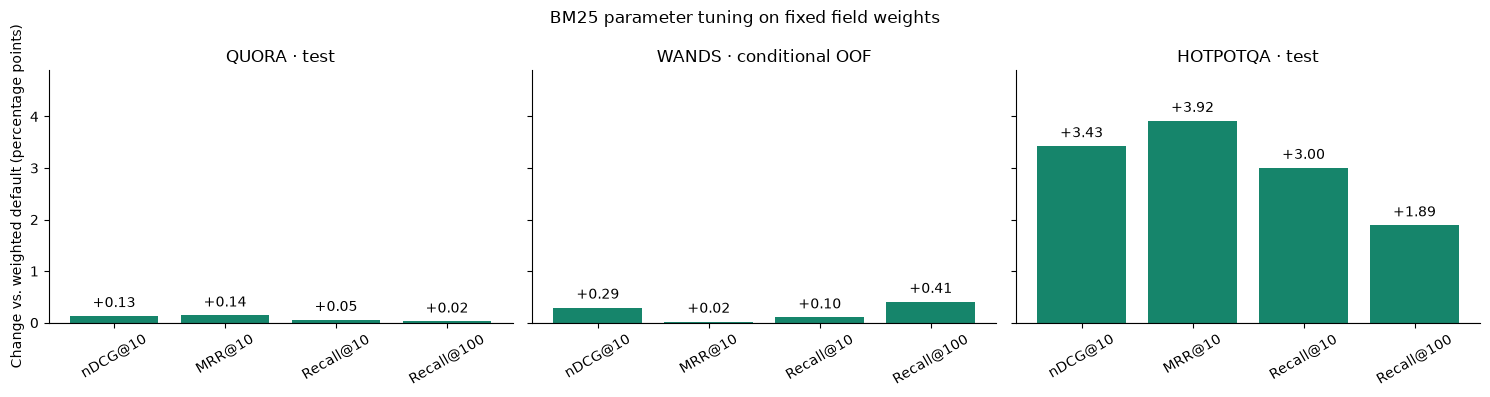

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(results), figsize=(5*len(results), 4), squeeze=False, sharey=True)
for ax, (name, tables) in zip(axes[0], results.items()):
    table = tables['summary'].set_index('method')
    baseline = table.loc['Weighted default', METRICS].astype(float)
    tuned = table.drop(index='Weighted default').iloc[0]
    delta = 100*(tuned[METRICS].astype(float)-baseline)
    bars = ax.bar(METRICS, delta, color=['#16856b' if v >= 0 else '#c65b46' for v in delta])
    ax.axhline(0, color='#555555', linewidth=0.8)
    ax.bar_label(bars, labels=[f'{v:+.2f}' if np.isfinite(v) else 'N/A' for v in delta], padding=4)
    protocol = 'conditional OOF' if name == 'wands' else 'test'
    ax.set_title(f'{name.upper()} · {protocol}')
    ax.tick_params(axis='x', labelrotation=30)
    ax.margins(y=0.25)
    ax.spines[['top', 'right']].set_visible(False)
axes[0, 0].set_ylabel('Change vs. weighted default (percentage points)')
fig.suptitle('BM25 parameter tuning on fixed field weights')
fig.tight_layout()
plt.show()